In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

Foi realizado o metodo cotovelo para saber qual seria o numero ideal k (clusters).Após a realização dele, foi possivel observar que o melhor valor de k seria 3, pois é onde se tem uma relação de custo beneficio maior (relação entre menor erro e menor numero de grupos)

c:\Users\Irisd\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\Irisd\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\Irisd\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\Irisd\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Window

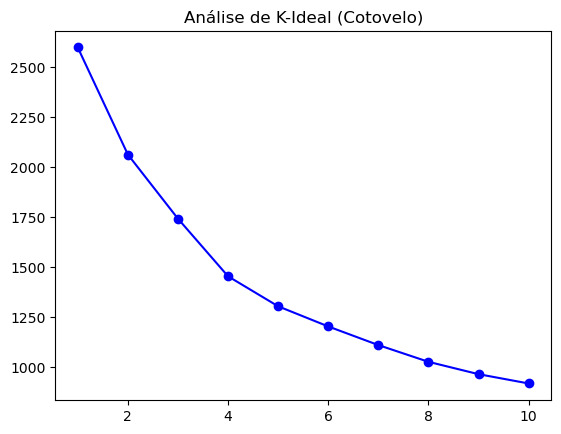

In [22]:
df = pd.read_csv("StudentStress.csv")
X = df.drop(columns=['Kindly Rate your Sleep Quality '])

X_std = StandardScaler().fit_transform(X)

lista = []
k = range(1,11)
for a in k:
    kmeans = KMeans(n_clusters=a,random_state=42,n_init=10)
    kmeans.fit(X_std)
    lista.append(kmeans.inertia_)

plt.figure(1)
plt.clf()
plt.plot(k, lista, 'bo-')
plt.title('Análise de K-Ideal (Cotovelo)')
plt.show()



Após isso foi realizado o Kmeans, que agrupou os grupos com suas caracteristicas parecidas retirando a coluna Kindly Rate your Sleep Quality, com isso se é visto que os grupos gerados tem qualidade de sono diferentes.

c:\Users\Irisd\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


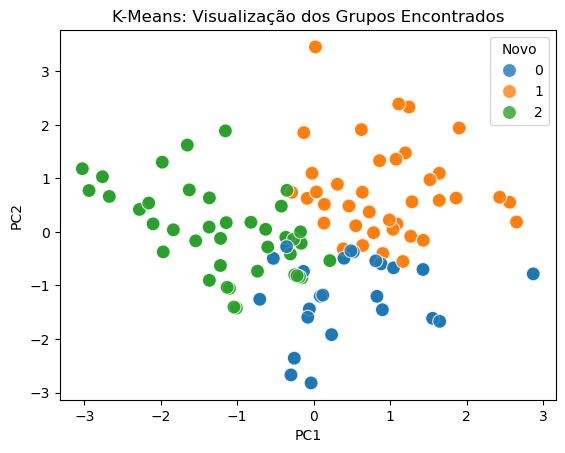

In [27]:
kmeans = KMeans(n_clusters=3,random_state=42,n_init= 10)
clusters = kmeans.fit_predict(X_std)


pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_std)
df_cluster = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_cluster['Novo'] = clusters
df['Novo'] = clusters

plt.figure(2)
plt.clf()
sns.scatterplot(data=df_cluster, x='PC1', y='PC2', hue='Novo', 
                palette='tab10', s=100, alpha=0.8)
plt.title('K-Means: Visualização dos Grupos Encontrados')
plt.show()

In [4]:
df.groupby('Novo').mean()

,Kindly Rate your Sleep Quality,How many times a week do you suffer headaches?,How would you rate you academic performance?,how would you rate your study load?,How many times a week you practice extracurricular activities?,How would you rate your stress levels?
Novo,,,,,,
0,3.240000,1.720000,4.20000,2.400000,4.240000,2.320000
1,3.102564,2.333333,3.25641,3.974359,2.820513,3.923077
2,3.075000,2.325000,2.85000,1.775000,1.575000,2.200000


Grupo 0: dorme bem, sofre pouco de dor de cabeça, tem uma perfomance academica muito boa, acha que estuda pouco, pratica exercicios regularmente e acha que tem nivel de estresse baixo

Grupo 1: Dorme bem, tem as vezes dor de cabeça, a performance academica é boa, estuda relativamente bastante, pratica atividade fisica as vezes e o nivel de estresse é relativamente alto

Grupo 2: Dorme bem mas menos que os outros, sofre as vezes de dor de cabeça, a perfomance academica é baixa, estuda pouco, pratica pouco exercicio fisico e o nivel de estresse é baixo